In [618]:
import pandas as pd
import numpy as np
import plotly.express as px

## Description

**Presentation**

Le dataset s’appelle **Glass Identification**. Il vient du UCI Machine Learning Repository . Il  provient du service de police scientifique des États-Unis. 

Il a été conçu pour la criminologie : un éclat de verre retrouvé sur une scène de crime peut servir de preuve, à condition d’identifier correctement son type.

214 échantillons, 9 variables de type réel, aucune valeur manquante. 

Chaque ligne est un échantillon de verre. Les variables sont l’indice de réfraction (RI) et la teneur en oxydes de Na, Mg, Al, Si, K, Ca, Ba et Fe, en pourcentage de poids.

## Importation et lecture du jeux données

In [619]:
from ucimlrepo import fetch_ucirepo
glass = fetch_ucirepo(id=42)
data = glass.data.features
data.head()

,RI,Na,Mg,Al,Si,K,Ca,Ba,Fe
0,1.52101,13.64,4.49,1.10,71.78,0.06,8.75,0.0,0.0
1,1.51761,13.89,3.60,1.36,72.73,0.48,7.83,0.0,0.0
2,1.51618,13.53,3.55,1.54,72.99,0.39,7.78,0.0,0.0
3,1.51766,13.21,3.69,1.29,72.61,0.57,8.22,0.0,0.0
4,1.51742,13.27,3.62,1.24,73.08,0.55,8.07,0.0,0.0


In [620]:
data.shape

(214, 9)

In [621]:
# Infos des données
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 214 entries, 0 to 213
Data columns (total 9 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   RI      214 non-null    float64
 1   Na      214 non-null    float64
 2   Mg      214 non-null    float64
 3   Al      214 non-null    float64
 4   Si      214 non-null    float64
 5   K       214 non-null    float64
 6   Ca      214 non-null    float64
 7   Ba      214 non-null    float64
 8   Fe      214 non-null    float64
dtypes: float64(9)
memory usage: 15.2 KB


In [622]:
data.duplicated().sum()

np.int64(1)

In [623]:
# Supprimer les doublons
data = data.drop_duplicates()

In [624]:
data.duplicated().sum()

np.int64(0)

In [625]:
# statistiques descriptives des données
data.describe()

,RI,Na,Mg,Al,Si,K,Ca,Ba,Fe
count,213.000000,213.000000,213.000000,213.000000,213.000000,213.000000,213.000000,213.000000,213.000000
mean,1.518348,13.404085,2.679202,1.449484,72.655070,0.498873,8.954085,0.175869,0.057277
std,0.003033,0.816662,1.443691,0.495925,0.773998,0.653185,1.425882,0.498245,0.097589
min,1.511150,10.730000,0.000000,0.290000,69.810000,0.000000,5.430000,0.000000,0.000000
25%,1.516520,12.900000,2.090000,1.190000,72.280000,0.130000,8.240000,0.000000,0.000000
50%,1.517680,13.300000,3.480000,1.360000,72.790000,0.560000,8.600000,0.000000,0.000000
75%,1.519150,13.810000,3.600000,1.630000,73.090000,0.610000,9.150000,0.000000,0.100000
max,1.533930,17.380000,4.490000,3.500000,75.410000,6.210000,16.190000,3.150000,0.510000


## Observations sur les statistiques descriptives

Il y a 214 valeurs pour chaque variable, donc aucune valeur manquante.

L’écart-type de RI est d’environ 0,003, celui de Si d’environ 0,77 et celui de Mg d’environ 1,44. RI ne pèserait presque rien dans les distances, et Mg ou Na domineraient.

Ba et Fe sont presque toujours nuls : le 75e percentile de Ba vaut 0 et celui de Fe vaut 0,10.

Quelques valeurs extrêmes : K monte à 6,21 alors que sa moyenne est de 0,50.

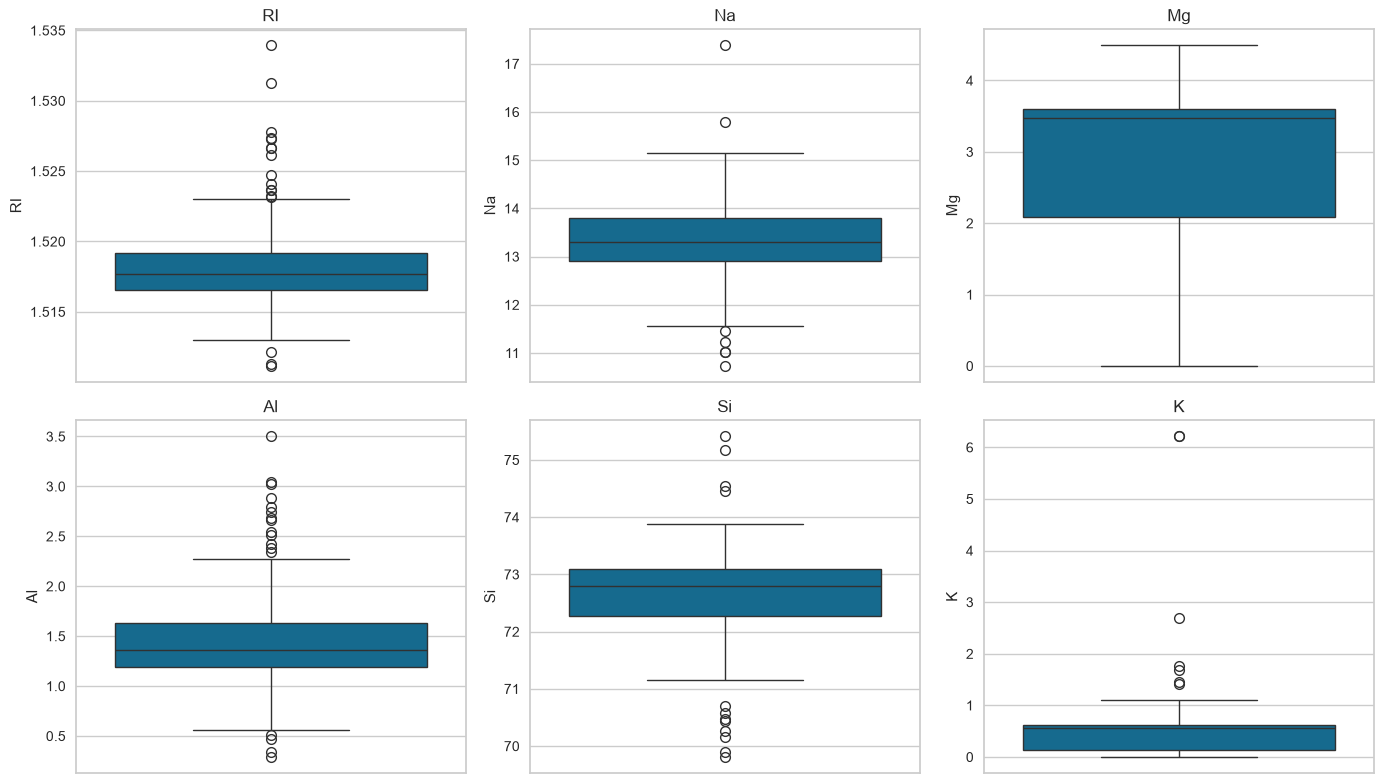

In [626]:
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
for ax, col in zip(axes.flat, data.columns):
    sns.boxplot(y=data[col], ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

**Interprétation des boxplots :**

Sur ces graphiques, on observe la distribution de nos variables et la présence de valeurs extrêmes avant de normaliser les données. On remarque d'abord que presque toutes les variables (RI, Na, Al, Si, K) ont des valeurs extrêmes en dehors des moustaches, surtout sur le potassium  avec deux points très hauts, et sur l'aluminium (Al). À l'inverse, le magnésium (Mg) n'a aucune valeur extrême. Enfin, on voit bien que les échelles sont très différentes d'une variable à l'autre , ce qui montre qu'il est indispensable de normaliser les données avant de faire le clustering.

In [627]:
# Renomme les index
for i in range(len(data)):
  data.rename(index = {
      i:"Verre" + str(i+1)
  }, inplace = True)

data.head()

,RI,Na,Mg,Al,Si,K,Ca,Ba,Fe
Verre1,1.52101,13.64,4.49,1.10,71.78,0.06,8.75,0.0,0.0
Verre2,1.51761,13.89,3.60,1.36,72.73,0.48,7.83,0.0,0.0
Verre3,1.51618,13.53,3.55,1.54,72.99,0.39,7.78,0.0,0.0
Verre4,1.51766,13.21,3.69,1.29,72.61,0.57,8.22,0.0,0.0
Verre5,1.51742,13.27,3.62,1.24,73.08,0.55,8.07,0.0,0.0


In [628]:
# Matrice des données
z = data.values
z[:5]

array([[1.52101e+00, 1.36400e+01, 4.49000e+00, 1.10000e+00, 7.17800e+01,
        6.00000e-02, 8.75000e+00, 0.00000e+00, 0.00000e+00],
       [1.51761e+00, 1.38900e+01, 3.60000e+00, 1.36000e+00, 7.27300e+01,
        4.80000e-01, 7.83000e+00, 0.00000e+00, 0.00000e+00],
       [1.51618e+00, 1.35300e+01, 3.55000e+00, 1.54000e+00, 7.29900e+01,
        3.90000e-01, 7.78000e+00, 0.00000e+00, 0.00000e+00],
       [1.51766e+00, 1.32100e+01, 3.69000e+00, 1.29000e+00, 7.26100e+01,
        5.70000e-01, 8.22000e+00, 0.00000e+00, 0.00000e+00],
       [1.51742e+00, 1.32700e+01, 3.62000e+00, 1.24000e+00, 7.30800e+01,
        5.50000e-01, 8.07000e+00, 0.00000e+00, 0.00000e+00]])

In [629]:
# Importation normalize
from sklearn.preprocessing import normalize
# Normaliser z
z = normalize(z)
z[:5]

array([[2.06246130e-02, 1.84955866e-01, 6.08835658e-02, 1.49157956e-02,
        9.73323464e-01, 8.13588852e-04, 1.18648374e-01, 0.00000000e+00,
        0.00000000e+00],
       [2.03504715e-02, 1.86258689e-01, 4.82743903e-02, 1.82369919e-02,
        9.75276780e-01, 6.43658537e-03, 1.04996799e-01, 0.00000000e+00,
        0.00000000e+00],
       [2.02815444e-02, 1.80987281e-01, 4.74874240e-02, 2.06001783e-02,
        9.76368191e-01, 5.21692827e-03, 1.04071031e-01, 0.00000000e+00,
        0.00000000e+00],
       [2.04044939e-02, 1.77604578e-01, 4.96109685e-02, 1.73436719e-02,
        9.76220168e-01, 7.66348293e-03, 1.10515491e-01, 0.00000000e+00,
        0.00000000e+00],
       [2.02789145e-02, 1.77341273e-01, 4.83779510e-02, 1.65714528e-02,
        9.76646591e-01, 7.35024118e-03, 1.07848084e-01, 0.00000000e+00,
        0.00000000e+00]])

## Application d'une ACP

In [630]:
# Importation PCA
from sklearn.decomposition import PCA
# avec n_components = 2
pca = PCA(n_components=2)
# Matrice des 2 composantes
features_pca = pca.fit_transform(z)
# Dataframe
data_pca = pd.DataFrame(features_pca, columns = ['PC1', 'PC2'])

In [631]:
# Part de variance 
round(sum(pca.explained_variance_ratio_*100),2)

np.float64(79.65)

## Kmeans

In [632]:
# Importation du KMeans
from sklearn.cluster import KMeans

## La méthode coude

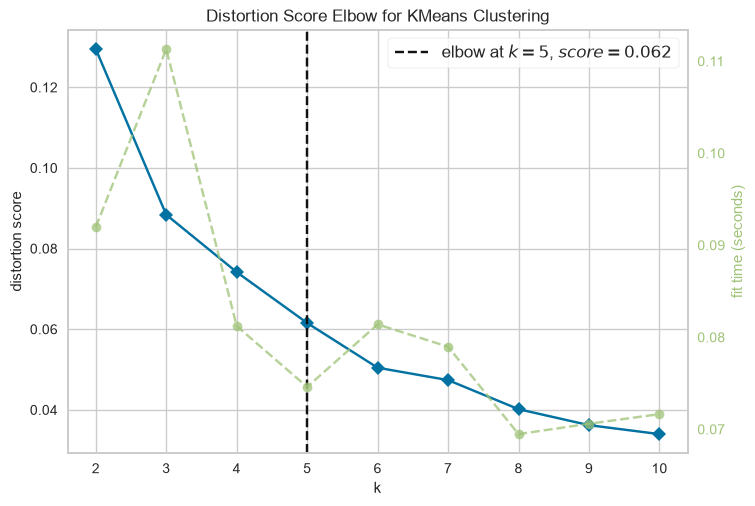

<Axes: title={'center': 'Distortion Score Elbow for KMeans Clustering'}, xlabel='k', ylabel='distortion score'>

In [633]:
# importation KELbowVisualizer
from yellowbrick.cluster import KElbowVisualizer
# Instantie le modèle kmeans
kmeans_model1 = KMeans(init = 'random', max_iter=500)
# Instantie KELbowVisualizer
Elbow_M = KElbowVisualizer(kmeans_model1, k=10)
# Entrainement du model
Elbow_M.fit(z)
# Visualiser 
Elbow_M.show()

**Interpretation**

Sur ce graphique, l'algorithme place automatiquement le coude à k = 5 (avec un score de 0,061).

Pourtant, à l'œil nu, on remarque que la courbe ralentit déjà fortement dès k = 3, avant de descendre de manière régulière jusqu'à k = 7.

## Appliquer Kmeans en utilisant le k optimal

In [634]:
# Initiation du modèle (k choisi)
kmeans_model1 = KMeans(n_clusters=3, init='random', max_iter=500, random_state=42, n_init=10)
# entraînement du modèle
kmeans_model1.fit(z)

KMeans(init='random', max_iter=500, n_clusters=3, n_init=10, random_state=42)

In [635]:
# Initiation du modèle (k choisi)
kmeans_model2 = KMeans(n_clusters=5, init='random', max_iter=500, random_state=42, n_init=10)
# entraînement du modèle
kmeans_model2.fit(z)

KMeans(init='random', max_iter=500, n_clusters=5, n_init=10, random_state=42)

## Prédiction la partition

In [636]:
# Prediction de la partition
kmeans_partition_k3 = kmeans_model1.predict(z)
# Affichage de la partition
kmeans_partition_k3

array([2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 1, 2, 1, 1, 1, 1, 1, 1,
       1, 1, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 1, 1, 1, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 0, 2, 1, 1, 1, 1, 1, 1, 0, 0, 1, 2, 1, 2,
       2, 2, 2, 0, 0, 1, 1, 0, 2, 2, 2, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0], dtype=int32)

In [637]:
# Prediction de la partition(
kmeans_partition_k5 = kmeans_model2.predict(z)
# Affichage de la partition
kmeans_partition_k5

array([2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 1, 1, 2, 2, 1,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 1, 2, 1, 2, 2, 2, 1, 2,
       1, 2, 1, 1, 1, 1, 1, 1, 2, 2, 2, 2, 2, 2, 2, 2, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 1, 1, 0, 0, 0, 0, 0, 0,
       0, 0, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 1, 1, 1, 0, 0, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 1, 1, 2, 2,
       2, 2, 1, 2, 2, 2, 1, 1, 3, 1, 0, 0, 0, 0, 0, 0, 3, 3, 0, 1, 0, 1,
       1, 1, 1, 2, 4, 0, 0, 4, 2, 2, 2, 1, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4,
       4, 4, 3, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4], dtype=int32)

In [638]:
# Nombre d'observations dans chaque classe
val1 = pd.Series(kmeans_partition_k3).value_counts()
val1

2    159
0     32
1     22
Name: count, dtype: int64

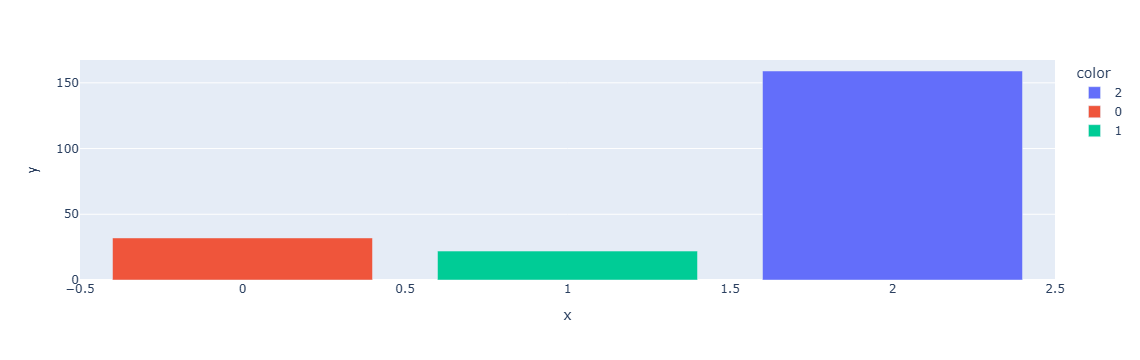

In [639]:
# Diagramme en barre du nombre d'observations dans chaque
import plotly.express as px
fig = px.bar(x = val1.index, y = val1.values ,color = val1.index.astype(str))
fig.show()

In [640]:
# Nombre d'observations dans chaque classe
val3 = pd.Series(kmeans_partition_k5).value_counts()
val3

2    124
1     39
4     26
0     20
3      4
Name: count, dtype: int64

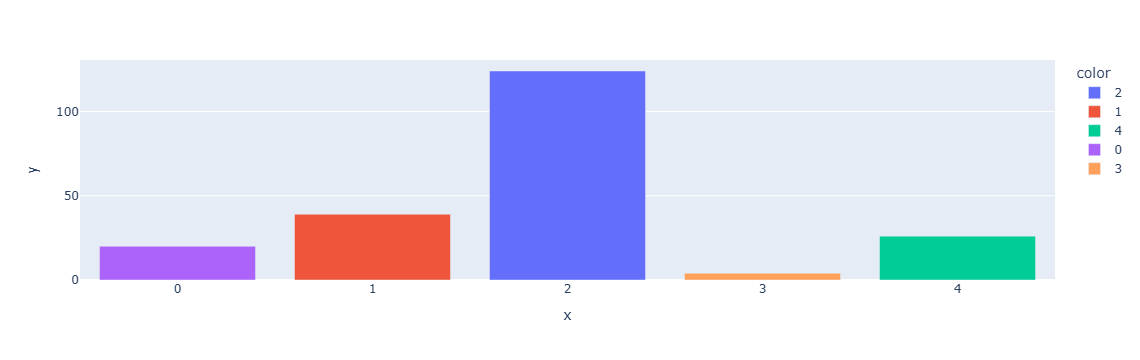

In [641]:
# Diagramme en barre du nombre d'observations dans chaque classe
import plotly.express as px
fig = px.bar(x = val3.index, y = val3.values ,color = val3.index.astype(str))
fig.show()

## Visualiser les classes prédictes par Kmeans

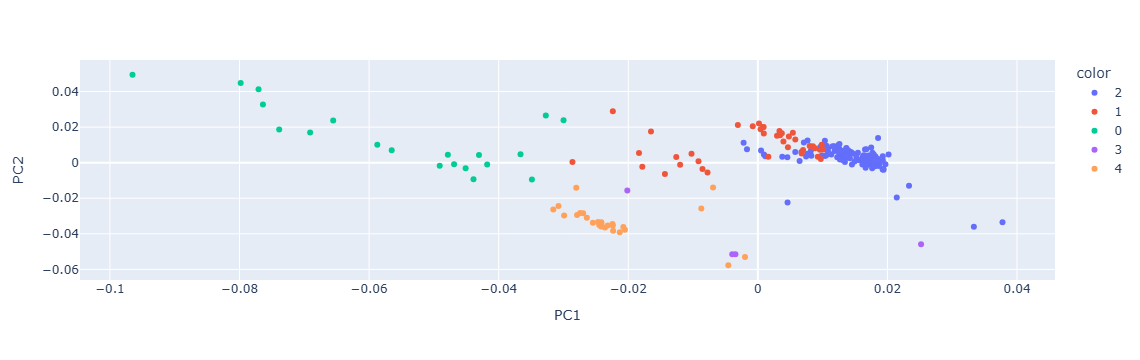

In [642]:
# Visualiser les classes suivant les deux composantes 
fig = px.scatter(data_pca, x = 'PC1', y = 'PC2', color = kmeans_partition_k5.astype(str))
fig.show()

**Interpretation**

Ce graphique représente la projection en 2D  des 5 clusters K-means : on voit que certains groupes sont bien séparés, mais que les clusters 1 et 2 se superposent et que le cluster 0 est minuscule.

In [643]:
# Indice de silhouette
# Importation silhouette score
from sklearn.metrics import silhouette_score
# Indice de Silhouette value
sil_kmeans_k5 = silhouette_score(z, kmeans_partition_k5)
print(f"Silhouette score : {sil_kmeans_k5 }")

Silhouette score : 0.43826909776750383


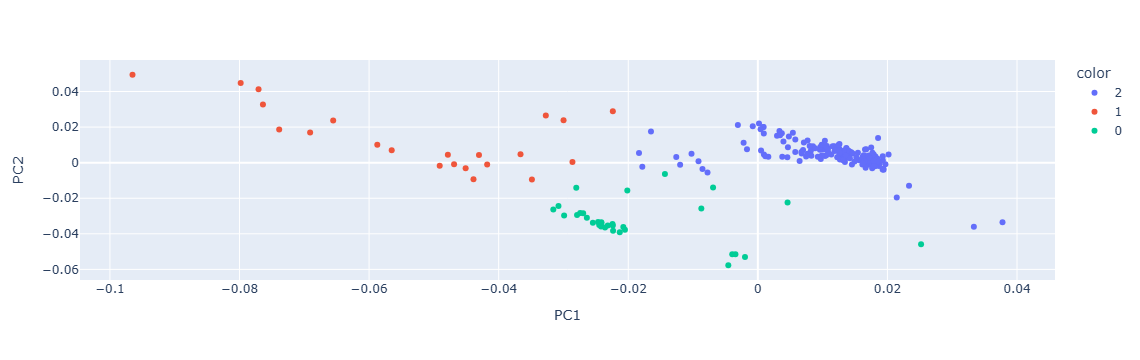

In [644]:
# Visualiser les classes suivant les deux composantes 
fig = px.scatter(data_pca, x = 'PC1', y = 'PC2', color = kmeans_partition1.astype(str))
fig.show()

**Interpretation**

Ce graphique montre la projection en 2D (ACP) des 3 clusters : ce découpage est beaucoup plus propre et lisible que celui à 5 clusters, car les trois groupes sont bien distincts et ne se mélangent presque plus.

In [645]:
# Importation silhouette score
from sklearn.metrics import silhouette_score
# Indice de Silhouette value
sil_kmeans_k3 = silhouette_score(z, kmeans_partition_k3)
print(f"Silhouette score : {sil_kmeans_k3 }")

Silhouette score : 0.5994861841736193


**Conclusion**

**Le découpage en 3 clusters (k = 3) s'impose comme le meilleur modèle. D'une part, la méthode du coude montrait déjà un premier ralentissement net à k = 3, et le score de silhouette confirme ce choix en atteignant 0,60 (contre 0,45 pour k = 5). D'autre part, la visualisation en 2D montre que les 3 groupes sont bien distincts et équilibrés, alors que le passage à 5 clusters fait apparaître des mélanges entre les groupes du centre et isole quelques points. Nous retenons donc le modèle à 3 clusters, qui offre la segmentation la plus claire, la plus fiable.**

## CAH

In [646]:
# Importation de linkage et dendrogram
from scipy.cluster.hierarchy import  linkage, dendrogram

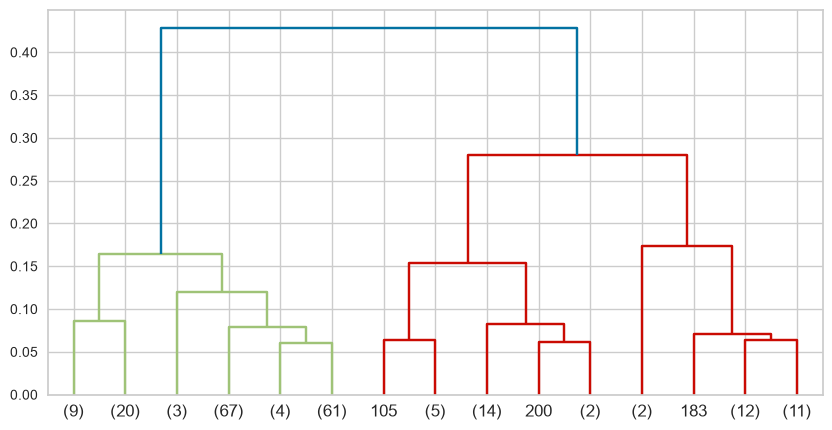

In [647]:
# Visualisation du dendrograme
from scipy.cluster.hierarchy import linkage, dendrogram
import matplotlib.pyplot as plt

Z = linkage(z, 'ward')
plt.figure(figsize=(10, 5))
dendrogram(Z, truncate_mode='lastp', p=15)
plt.show()

**Interpretation**

Sur ce dendrogramme, on voit comment les données se regroupent en 3 clusters. On remarque d'abord un grand bloc vert à gauche en dessous de 0,17. À droite du bloc vert, le reste des données forme deux autres groupes en rouge qui se rejoignent vers 0,28. Cela confirme visuellement que nos 3 clusters sont bien séparés.

In [648]:
from sklearn.cluster import AgglomerativeClustering
cah_modelk3 = AgglomerativeClustering(n_clusters =3, linkage = 'ward')
# entraînement du modèle
cah_modelk3.fit(z)

AgglomerativeClustering(n_clusters=3)

In [649]:
# Prédiction de la partition des données
cah_partitionk3 = cah_modelk3.fit_predict(z)
# Affichage de la partition
cah_partitionk3[:100]

array([1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1])

In [650]:
# Nombre d'observations dans chaque classe
val  = pd.Series(cah_partitionk3).value_counts()
val

1    164
0     26
2     23
Name: count, dtype: int64

In [651]:
# Function de visualisation du diagramme en barre des nombres d'observations.
def bar_plot(val):
  fig = px.bar(x = val.index.astype(str), y = val.values, color = val.index.astype(str), text_auto = True)
  fig.show()

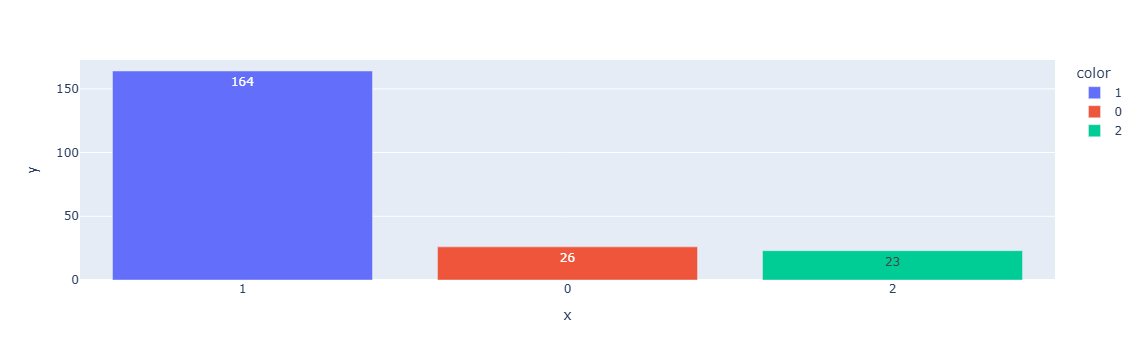

In [652]:
# Diagramme en barre des nombres d'observations
bar_plot(val)

In [653]:
# Function de visualisuation des classes
def scatter_plot(data_pca,Pred):
  fig = px.scatter(data_pca, x='PC1', y='PC2', color=Pred.astype(str))
  fig.show()

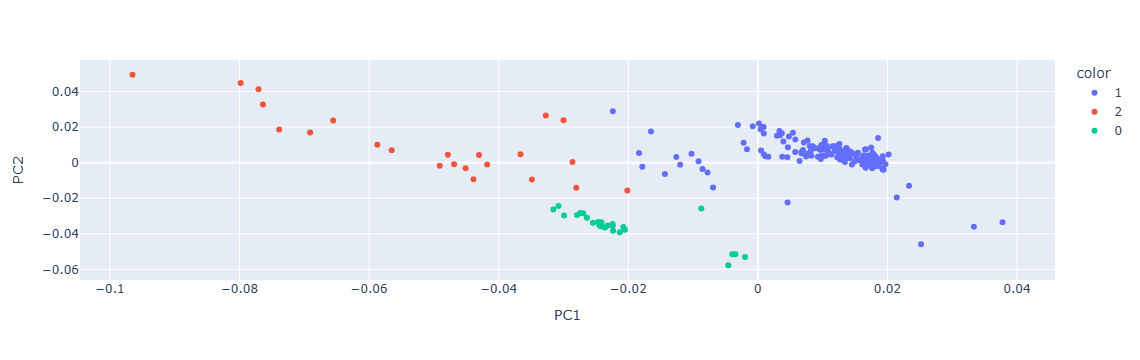

In [654]:
# Visualisation des classes
scatter_plot(data_pca, cah_partitionk3)

In [655]:
# Silhouette score
sil_cah3 = silhouette_score(z, cah_partitionk3)
print(f"La silhouette score :{sil_cahk3}")

La silhouette score :0.6063435618266342


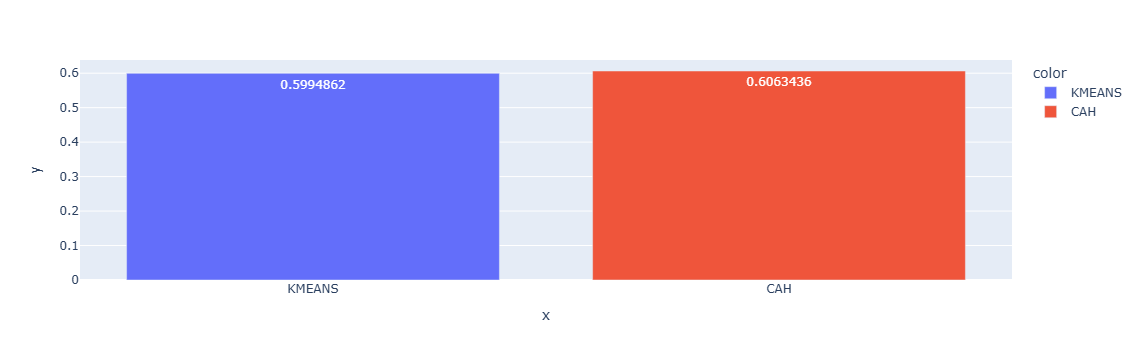

In [656]:
# Diagrammes en barre des silhouettes
Model_Names = ['KMEANS', 'CAH']
sil = [sil_kmeans_k3, sil_cahk3]
fig = px.bar(x= Model_Names, y = sil, color = Model_Names, text_auto = True)
fig.show()

## Choix de la CAH

Pour finir, j’ai comparé K-Means et la CAH avec 3 groupes, et j’ai retenu la CAH.
D’abord, la CAH a un meilleur score de silhouette que K-Means, 0,60 contre 0,59. Quand on regarde le dendrogramme et la projection en 2D, la CAH sépare bien les verres en 3 groupes clairs et cohérents, sans mélanger les points au centre.
K-Means donne aussi un bon découpage en 3 groupes, mais ses clusters sont un peu moins bien séparés, ce qui explique son score de silhouette légèrement plus bas.
Enfin, les 3 groupes de la CAH sont très faciles à interpréter chimiquement : on voit tout de suite quel type de verre se trouve dans chaque groupe.
Donc, la CAH est le modèle le plus précis et le plus adapté ici.

In [657]:
# les verres
cluster_names = []
for i in range(2):
  cluster_names.append(list(data.index[cah_partitionk3 == i]))

In [658]:
# Les verres de la classe 0
print(cluster_names[0])

['Verre172', 'Verre173', 'Verre185', 'Verre190', 'Verre192', 'Verre193', 'Verre194', 'Verre195', 'Verre196', 'Verre197', 'Verre198', 'Verre199', 'Verre200', 'Verre201', 'Verre203', 'Verre204', 'Verre205', 'Verre206', 'Verre207', 'Verre208', 'Verre209', 'Verre210', 'Verre211', 'Verre212', 'Verre213', 213]


## Déploiement du meilleur modèle  avec Gradio

In [660]:
import numpy as np
import tqdm as notebook_tqdm
import gradio as gr
from scipy.spatial.distance import cdist

# Calcule des centroïdes
classes = np.unique(cah_partitionk3)
centroides = np.array([z[cah_partitionk3 == c].mean(axis=0) for c in classes])

# Prédiction : la classe du centroïde le plus proche
def predire_classe_km(nouveau_verre):
    verre = normalize(np.array(nouveau_verre, dtype=float).reshape(1, -1))
    distances = cdist(verre, centroides)
    return classes[distances.argmin()]


In [661]:
# Test rapide
print("Classe prédite :", predire_classe_km(data.iloc[0].values))
print("Classe réelle de cah :", cah_partitionk3[3])

Classe prédite : 1
Classe réelle de cah : 1


In [662]:
# Profil moyen de chaque classe 
profil = data.groupby(cah_partitionk3).mean().round(2)
profil

,RI,Na,Mg,Al,Si,K,Ca,Ba,Fe
0,1.52,14.62,0.07,2.22,72.99,0.56,8.44,1.02,0.02
1,1.52,13.29,3.43,1.34,72.60,0.50,8.60,0.05,0.06
2,1.52,12.86,0.31,1.37,72.67,0.39,12.06,0.14,0.07


In [663]:
# Noms des classes adaptés aux 3 clusters de verre
noms_classes = {
    0: "Verre technique ",
    1: "Verre standard ",
    2: "Verre spécial."
}


## Interpretation des classes

Pour interpréter les groupes, j’ai calculé la composition moyenne de chaque groupe, puis je l’ai comparée à la moyenne de tous les verres. Comme ça, je vois ce qui caractérise chaque groupe.

**Groupe 1 : Verre standard**

C’est le groupe le plus courant. Sa composition est proche de la moyenne dans presque tous les éléments, avec beaucoup de magnésium (Mg à 3,43 en moyenne). Par contre, il ne contient presque pas de baryum (Ba à 0,05) ni de fer.

**Groupe 0 : Verre technique**

Ce sont les verres les plus riches en sodium (Na à 14,62), en aluminium (Al à 2,22) et surtout en baryum (Ba à 1,02, soit presque 6 fois la moyenne). En revanche, ils ne contiennent presque pas de magnésium (Mg à 0,07).

**Groupe 2 : Verre spécial**

Ce sont les plus gros consommateurs de calcium (Ca), avec plus de 12,06 en moyenne (contre 8,95 pour l'ensemble). Ils ont aussi un peu plus de fer (Fe à 0,07) et de baryum (Ba à 0,14) que les verres standards, mais contiennent très peu de magnésium (Mg à 0,31) et de potassium (K).

In [667]:
def affecter_verre(*valeurs):
    if any(v is None or v < 0 for v in valeurs):
        raise gr.Error("Aucun champ ne peut être vide ou négatif.")
    verre = normalize(np.array(valeurs, dtype=float).reshape(1, -1))
    g = int(classes[cdist(verre, centroides).argmin()])
    return f"Groupe {g} : {noms_classes[g]}"

In [668]:
import gradio as gr

# Un champ par variable, prérempli avec la valeur médiane
champs = [gr.Number(label=col, value=float(data[col].median()))
          for col in data.columns]
exemples = data.head(3).values.tolist()
interface = gr.Interface(
    fn=affecter_verre,
    inputs=champs,
    outputs=gr.Textbox(label="Résultat"),
    title="Segmentation des verres - modèle CAH",
    description="Saisissez la composition d'un verre pour connaître son groupe.",
    examples=exemples,
)

In [669]:
# Lancer l'application
interface.launch(share=True)

* Running on local URL:  http://127.0.0.1:7865

Could not create share link. Please check your internet connection or our status page: https://status.gradio.app.


In [670]:
import joblib
joblib.dump({
    "methode": "CAH",
    "cah_modelk3": cah_modelk3,
    "centroides": centroides,
    "classes": np.array([0, 1, 2]),
    "colonnes": list(data.columns),
    "descriptions": noms_classes,
    "normalisation": "normalize",
    "medianes": data.median().to_dict()
}, "modeles/verre.pkl")

['modeles/verre.pkl']